# Quick-Commerce Delivery Intelligence
## Consolidated Analysis Notebook — PS1 to PS8

**Purpose.** This notebook provides a reproducible, evidence-led walkthrough of the supplied project: data quality, delay definition, EDA, saved regression/classification results, geographic demand clustering, rider segmentation, explainability, and exactly three management actions.

**Important:** This notebook reads the project's existing processed data, JSON reports, prediction outputs, and saved artifacts. It does **not** retrain models or retune the classifier. The 30-minute SLA is provisional. The source is a food-delivery dataset used as a quick-commerce proxy, not verified grocery dark-store operations data.

## 0. Environment and project paths
Run this notebook from the `Quick_Commerce` project root, or keep the notebook in `submission/` and let the path resolver locate the root.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve project root whether launched from the root or submission/
CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT = next((p for p in CANDIDATES if (p / "artifacts/metrics/regression_results.json").exists()), None)
if PROJECT is None:
    raise FileNotFoundError("Project root not found. Open this notebook from Quick_Commerce/ or Quick_Commerce/submission/.")
REPORTS = PROJECT / "reports"
METRICS = PROJECT / "artifacts/metrics"
DATA = PROJECT / "data/processed/cleaned_orders.csv"

def load_json(name):
    with open(METRICS / name, encoding="utf-8") as f: return json.load(f)
def load_report(name):
    with open(REPORTS / name, encoding="utf-8") as f: return json.load(f)

print("Project:", PROJECT.resolve())
print("Processed data exists:", DATA.exists())
print("Metrics directory exists:", METRICS.exists())

Project: E:\Manthan_calibo\Quick_Commerce
Processed data exists: True
Metrics directory exists: True


## 1. Challenge scope and analytical contract (PS1–PS2)
The official challenge requires a trustworthy data audit; a transparent definition of delivery time and lateness; Haversine store-to-customer distance; and exclusion of information unavailable at order placement. The project defines lateness as delivery time **strictly greater than** the configured 30-minute provisional SLA.

In [2]:
SLA_MINUTES = 30  # provisional; confirm with challenge organiser
raw_path = PROJECT / "data/raw/train.csv"
processed = pd.read_csv(DATA)
print(f"Processed rows: {len(processed):,}; columns: {processed.shape[1]}")
display(processed.head())
print("Columns:", processed.columns.tolist())

Processed rows: 45,593; columns: 46


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,is_late_order,rider_age_suspicious,rating_out_of_range,multiple_deliveries_invalid,vehicle_condition_invalid,delivery_time_invalid,delivery_time_iqr_outlier,delivery_time_percentile_outlier,distance_iqr_outlier,distance_percentile_outlier
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,...,False,False,False,False,False,False,False,False,False,False
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,...,True,False,False,False,False,False,False,False,False,False
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,...,False,False,False,False,False,False,False,False,False,False
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,...,False,False,False,False,False,False,False,False,False,False
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,...,False,False,False,False,False,False,False,False,False,False


Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)', 'coordinate_range_valid', 'coordinates_valid', 'zero_coordinate_pair', 'geographically_implausible_pair', 'raw_haversine_distance_km', 'delivery_distance_km', 'distance_over_review_threshold', 'order_hour', 'order_day', 'day_of_week', 'is_weekend', 'is_peak_hour', 'distance_band', 'weather_normalized', 'traffic_normalized', 'rider_age_band', 'is_late_order', 'rider_age_suspicious', 'rating_out_of_range', 'multiple_deliveries_invalid', 'vehicle_condition_invalid', 'delivery_time_invalid', 'delivery_time_iqr_outlier', 'delivery_time_percentile_outlier', 'distance_iqr_outlier', 'distanc

### PS1 — Data quality snapshot

In [3]:
quality_path = REPORTS / "data_quality_report.json"
if quality_path.exists():
    quality = json.load(open(quality_path, encoding="utf-8"))
    print(json.dumps(quality, indent=2)[:12000])
else:
    print("Data quality JSON not found; see reports/data_quality_report.md")

print("Exact duplicate rows:", int(processed.duplicated().sum()))
print("Missing values (top 15):")
display(processed.isna().sum().sort_values(ascending=False).head(15).rename("missing_count").to_frame())

{
  "dataset_overview": {
    "source_path": "E:\\Manthan_calibo\\Quick_Commerce\\data\\raw\\train.csv",
    "source_sha256": "d293b6fc7157aef30fb34301216a3432ec895d407ce2ea9edddf942b416cdde1",
    "rows": 45593,
    "columns": 20,
    "column_names": [
      "ID",
      "Delivery_person_ID",
      "Delivery_person_Age",
      "Delivery_person_Ratings",
      "Restaurant_latitude",
      "Restaurant_longitude",
      "Delivery_location_latitude",
      "Delivery_location_longitude",
      "Order_Date",
      "Time_Orderd",
      "Time_Order_picked",
      "Weatherconditions",
      "Road_traffic_density",
      "Vehicle_condition",
      "Type_of_order",
      "Type_of_vehicle",
      "multiple_deliveries",
      "Festival",
      "City",
      "Time_taken(min)"
    ],
    "loaded_dataframe_memory_bytes": 14109430,
    "column_profiles": [
      {
        "column": "ID",
        "raw_preservation_dtype": "string",
        "inferred_csv_dtype": "str",
        "cleaned_dtype": "string",


,missing_count
distance_percentile_outlier,4071
delivery_distance_km,4071
distance_band,4071
distance_iqr_outlier,4071
Delivery_person_Ratings,1908
rider_age_band,1892
Delivery_person_Age,1854
Time_Orderd,1731
order_hour,1731
is_peak_hour,1731


### PS2 — Prediction-time feature contract
The saved model metadata is the source of truth for the deployed prediction feature list. Pickup time and the delivery-time target are not valid predictors for an order-placement prediction.

In [4]:
reg = load_json("regression_results.json")
clf = load_json("classification_results.json")
print("Regression target:", reg["metadata"].get("target_column"))
print("Regression features:", reg["metadata"].get("feature_columns"))
print("Classification target:", clf["metadata"].get("target_column"))
print("Classification features:", clf["metadata"].get("feature_columns"))
print("SLA:", reg["metadata"].get("sla_threshold_minutes"), reg["metadata"].get("sla_status"))
print("Excluded fields:")
print(json.dumps(clf["metadata"].get("excluded_prediction_fields", {}), indent=2))

Regression target: Time_taken(min)
Regression features: ['delivery_distance_km', 'order_hour', 'order_day', 'day_of_week', 'is_weekend', 'is_peak_hour', 'distance_band', 'City', 'Type_of_order']
Classification target: is_late
Classification features: ['delivery_distance_km', 'order_hour', 'order_day', 'day_of_week', 'is_weekend', 'is_peak_hour', 'distance_band', 'City', 'Type_of_order']
SLA: 30 provisional
Excluded fields:
{
  "Time_taken(min)": "Outcome used only to construct the label.",
  "ID": "Order identifier; not a predictor.",
  "Delivery_person_ID": "Rider assignment timing is unknown.",
  "Time_Order_picked": "Known after order placement.",
  "rider_and_vehicle_fields": "Assignment timing is unverified.",
  "weather_normalized/Road_traffic_density": "Availability at order placement is unverified; included only as retrospective dashboard context, never as model features."
}


### Distance calculation
The project feature-engineering module calculates store-to-customer distance using validated coordinates and Haversine distance. Invalid coordinate pairs remain unavailable rather than being treated as genuine locations. The notebook uses the already processed distance field and does not silently recompute or alter the pipeline.

In [5]:
distance_col = "delivery_distance_km"
if distance_col in processed:
    display(processed[distance_col].describe().to_frame("delivery_distance_km"))
    print("Valid distance observations:", int(processed[distance_col].notna().sum()))
else:
    print("Distance feature not found in processed dataset; inspect feature_engineering.py")

,delivery_distance_km
count,41522.000000
mean,9.720129
std,5.603027
min,1.465067
25%,4.657655
50%,9.193021
75%,13.680920
max,20.969489


Valid distance observations: 41522


## 2. Diagnose delay patterns (PS3)

{
  "source": "E:\\Manthan_calibo\\Quick_Commerce\\data\\processed\\cleaned_orders.csv",
  "sla_threshold_minutes": 30,
  "sla_status": "provisional",
  "quality": {
    "input_records": 45593,
    "records_retained_by_preparation": 45593,
    "records_excluded_by_preparation": 0,
    "valid_delivery_time_records": 45593,
    "missing_or_invalid_delivery_time_records": 0,
    "missing_order_date_records": 0,
    "missing_order_time_records": 1731,
    "valid_coordinate_distance_records": 41522,
    "invalid_coordinate_records": 4071,
    "missing_coordinate_records": 0,
    "invalid_or_missing_coordinate_records": 4071,
    "unavailable_distance_records": 4071,
    "missing_rating_records": 1908,
    "invalid_rating_records": 53,
    "invalid_or_missing_rating_records": 1961,
    "missing_weather_records": 616,
    "missing_traffic_records": 601,
    "missing_order_type_records": 0,
    "missing_city_records": 1200
  },
  "delivery_time": {
    "order_count": 45593,
    "mean_minutes":

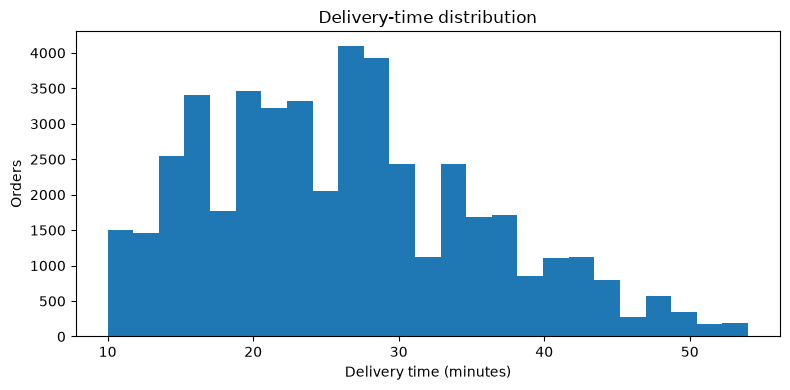

,count,mean,median
Road_traffic_density,,,
Jam,14143,31.176624,31.0
High,4425,27.240000,27.0
Medium,10947,26.699644,27.0
NaN,601,26.542429,26.0
Low,15477,21.266977,20.0


In [6]:
delay_path = REPORTS / "delay_analysis.json"
if delay_path.exists():
    delay = json.load(open(delay_path, encoding="utf-8"))
    print(json.dumps(delay, indent=2)[:14000])
else:
    print("Saved delay analysis report not found.")

# Compact descriptive plots from the processed dataset where fields are available
target = "Time_taken(min)"
if target in processed:
    plt.figure(figsize=(8,4)); processed[target].dropna().plot(kind="hist", bins=25)
    plt.xlabel("Delivery time (minutes)"); plt.ylabel("Orders"); plt.title("Delivery-time distribution"); plt.tight_layout(); plt.show()
if "Road_traffic_density" in processed and target in processed:
    display(processed.groupby("Road_traffic_density", dropna=False)[target].agg(["count","mean","median"]).sort_values("mean", ascending=False))

**Interpretation boundary:** The dataset contains no verified rider tenure/experience field. Rider age is not a valid substitute for experience. Any rider-experience comparison is therefore unavailable and must remain a documented limitation.

## 3. Delivery-time regression (PS4)

In [7]:
reg_table = pd.DataFrame([
    {"Model": x["model"], "CV MAE (min)": x.get("cv_mae_minutes"),
     "Test MAE (min)": x.get("test_metrics", {}).get("mae_minutes"),
     "Test RMSE (min)": x.get("test_metrics", {}).get("rmse_minutes"),
     "Test R²": x.get("test_metrics", {}).get("r2")}
    for x in reg["model_comparison"]
])
display(reg_table.sort_values("Test MAE (min)"))
print("Selected:", reg["metadata"]["selected_model"])
print("Selection interpretation:", reg.get("interpretation", "Not provided in saved report."))
print("Training configuration:", json.dumps(reg["metadata"].get("training_configuration", {}), indent=2))
print("Selected test metrics:", reg["selected_model_test_metrics"])

,Model,CV MAE (min),Test MAE (min),Test RMSE (min),Test R²
4,XGBoost,6.358243,6.403995,7.983190,0.273122
3,Gradient Boosting,6.350785,6.405533,7.983590,0.273049
1,Linear Regression,6.557943,6.630747,8.259865,0.221866
2,Random Forest,6.784271,6.802949,8.531580,0.169829
0,Mean Baseline,7.585195,7.579005,9.363726,-0.000014


Selected: Gradient Boosting
Selection interpretation: Permutation importance measures the change in held-out MAE when a feature is shuffled. It is an association with model performance, not a causal effect. The dataset does not confirm real-time feature availability.
Training configuration: {
  "random_seed": 42,
  "random_test_fraction": 0.2,
  "cv_folds": 3,
  "cv_scoring": "negative mean absolute error",
  "search_iterations_per_model": 3,
  "temporal_validation_fraction_of_training_dates": 0.2,
  "temporal_validation_start_date": "2022-03-29",
  "temporal_validation_skip_reason": null,
  "test_rows": 9119,
  "training_rows": 36474,
  "development_rows": 28920,
  "temporal_validation_rows": 7554,
  "input_rows": 45593,
  "valid_target_rows": 45593,
  "excluded_invalid_target_rows": 0,
  "selection_criterion": "Lowest training-only cross-validated MAE; chronological validation and held-out test metrics are reported separately.",
  "test_set_used_for_tuning": false,
  "preprocessing_f

,feature,mae_increase_minutes,standard_deviation_minutes
0,is_peak_hour,0.665065,0.031899
1,delivery_distance_km,0.541758,0.016415
2,City,0.293529,0.003610
3,order_hour,0.197134,0.016400
4,distance_band,0.023336,0.002380
5,order_day,0.003569,0.000324
6,Type_of_order,0.000287,0.000152
7,day_of_week,0.000240,0.000218
8,is_weekend,0.000000,0.000000


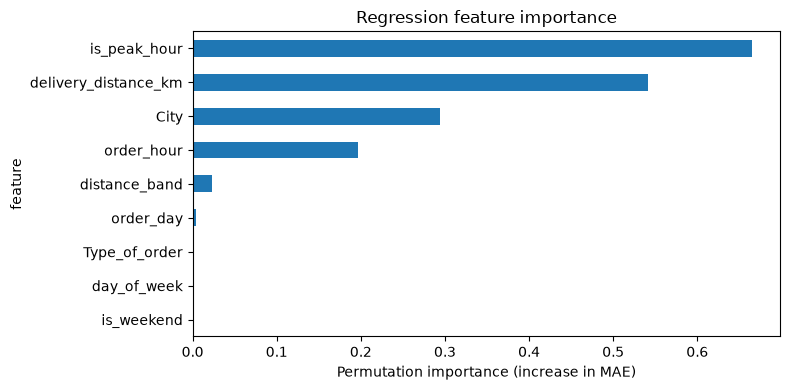

In [8]:
reg_imp = pd.DataFrame(reg.get("feature_importance", []))
if not reg_imp.empty:
    display(reg_imp)
    metric = "mae_increase_minutes" if "mae_increase_minutes" in reg_imp else reg_imp.columns[-1]
    plt.figure(figsize=(8,4)); reg_imp.sort_values(metric).plot.barh(x="feature", y=metric, legend=False, ax=plt.gca())
    plt.xlabel("Permutation importance (increase in MAE)"); plt.title("Regression feature importance"); plt.tight_layout(); plt.show()

**Result interpretation:** The selected Gradient Boosting model has held-out MAE around 6.406 minutes, RMSE around 7.984 minutes, and R² around 0.273 in the reported experiment. XGBoost is marginally lower in test MAE, but the difference is practically negligible; selection should follow the documented training-only validation criterion, not test-set tuning.

## 4. Late-order classification (PS5)

In [9]:
comp = clf["model_comparison"]
cls_table = pd.DataFrame([
    {"Model": x["model"], "Validation threshold": x.get("validation_threshold"),
     "Validation F2": x.get("validation_metrics", {}).get("f_beta"),
     "Validation recall": x.get("validation_metrics", {}).get("recall"),
     "Validation precision": x.get("validation_metrics", {}).get("precision")}
    for x in comp
])
display(cls_table)
selected = clf["selected_model"]
print("Selected model:", selected.get("name"))
print("Threshold:", selected.get("threshold"))
print("Held-out test metrics:", selected.get("test_metrics"))

,Model,Validation threshold,Validation F2,Validation recall,Validation precision
0,Logistic Regression,0.15,0.725907,0.905834,0.404513
1,Random Forest,0.15,0.733748,0.942582,0.389005
2,Gradient Boosting,0.15,0.745405,0.946256,0.403131
3,XGBoost,0.15,0.742599,0.937988,0.405078


Selected model: Gradient Boosting
Threshold: 0.15
Held-out test metrics: {'threshold': 0.15, 'order_count': 9119, 'true_negatives': 2431, 'false_positives': 3967, 'false_negatives': 146, 'true_positives': 2575, 'flagged_orders': 6542, 'accuracy': 0.5489637021603246, 'precision': 0.3936105166615714, 'recall': 0.946343256155825, 'f1': 0.5559753859440786, 'f_beta': 0.7388385171582692, 'specificity': 0.3799624882775867, 'balanced_accuracy': 0.6631528722167059, 'roc_auc': 0.7835249530730098, 'pr_auc': 0.5822754544626216, 'brier_score': 0.16498660091054504, 'confusion_matrix': {'labels': ['On time', 'Late'], 'values': [[2431, 3967], [146, 2575]]}}


In [10]:
tm = selected.get("test_metrics", {})
cm = np.array([[tm.get("true_negatives", np.nan), tm.get("false_positives", np.nan)],
               [tm.get("false_negatives", np.nan), tm.get("true_positives", np.nan)]])
if not np.isnan(cm).all():
    display(pd.DataFrame(cm, index=["Actual on-time","Actual late"], columns=["Predicted on-time","Predicted late"]))
print("Threshold rationale: selected by training-only validation F2; not proven cost-optimal.")
print("A 0.15 threshold has a substantial false-positive burden; operational alert capacity and intervention costs are not measured.")

,Predicted on-time,Predicted late
Actual on-time,2431,3967
Actual late,146,2575


Threshold rationale: selected by training-only validation F2; not proven cost-optimal.
A 0.15 threshold has a substantial false-positive burden; operational alert capacity and intervention costs are not measured.


## 5. Dark-store demand-zone discovery (PS6)

In [11]:
zones = load_json("demand_zone_results.json")
zm = zones["metadata"]
print("Selected K:", zm["selected_cluster_count"])
print("Silhouette:", zm["selected_silhouette_score"])
print("Elbow suggestion:", zm["inertia_elbow_suggestion"])
print("Selection at candidate boundary:", zm["silhouette_selection_at_candidate_boundary"])
ze = pd.DataFrame(zones["cluster_count_evaluation"])
display(ze)
clusters = pd.DataFrame(zones["clusters"])
display(clusters[[c for c in ["cluster_id","order_count","demand_share","mean_delivery_minutes","late_rate","average_delivery_distance_km","unique_riders"] if c in clusters]])

Selected K: 10
Silhouette: 0.7653803263852529
Elbow suggestion: 3
Selection at candidate boundary: True


,cluster_count,inertia_km_squared,silhouette_score,smallest_cluster_orders,largest_cluster_orders
0,2,9.846048e+09,0.507128,17013,24940
1,3,5.200552e+09,0.560605,10158,17013
2,4,2.830073e+09,0.625135,3832,17013
3,5,1.948085e+09,0.622152,3790,15260
4,6,1.390262e+09,0.648639,3181,13223
5,7,1.083310e+09,0.674365,3145,10078
6,8,8.133134e+08,0.725087,3145,10078
7,9,5.800086e+08,0.740205,1244,10078
8,10,4.190188e+08,0.765380,1179,10078


,cluster_id,order_count,demand_share,mean_delivery_minutes,late_rate,average_delivery_distance_km,unique_riders
0,0,3637,0.086692,26.195491,0.295848,9.492616,102
1,1,10078,0.240221,26.139710,0.291228,9.712482,237
2,2,3264,0.077801,26.387255,0.302083,9.396320,108
3,3,4763,0.113532,26.273777,0.296242,9.617074,90
4,4,3993,0.095178,26.684448,0.318808,10.332594,102
5,5,3181,0.075823,26.431311,0.304936,9.629039,60
6,6,7469,0.178033,26.236310,0.295756,9.561927,219
7,7,1244,0.029652,26.730707,0.314309,10.494390,99
8,8,1179,0.028103,26.402884,0.324003,10.118822,93
9,9,3145,0.074965,26.358983,0.294436,9.741410,60


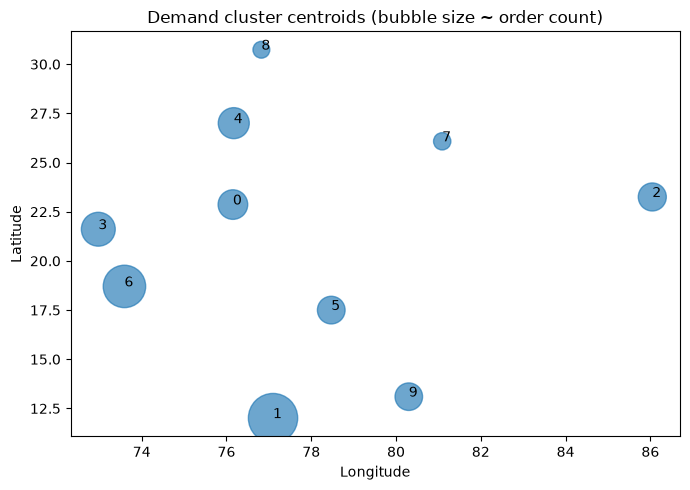

Limitations:
- The source has delivery orders, not distinct customer IDs; order count is demand proxy, not unique demanding customers.
- Clusters describe customer order density, not an optimal dark-store location.
- Restaurants are an imperfect proxy for existing operational coverage; dark-store footprints are not supplied.
- Candidate ranking omits property availability, rent, inventory, road access, staffing, capacity, and operational feasibility.
- Straight-line geographic density and delivery outcomes do not establish causal benefit from opening a site.


In [12]:
if {"centroid_latitude","centroid_longitude","order_count"}.issubset(clusters.columns):
    plt.figure(figsize=(7,5)); plt.scatter(clusters.centroid_longitude, clusters.centroid_latitude, s=clusters.order_count/8, alpha=.65)
    for _, r in clusters.iterrows(): plt.annotate(str(int(r.cluster_id)), (r.centroid_longitude, r.centroid_latitude))
    plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title("Demand cluster centroids (bubble size ~ order count)"); plt.tight_layout(); plt.show()
print("Limitations:", *zones.get("limitations", []), sep="\n- ")

**Important:** The saved PS6 report indicates K=10 was selected at the tested candidate boundary, while the elbow suggestion was K=3. Treat the result as exploratory, not a confirmed optimal store-location decision. Customer order volume is a demand proxy, and restaurant locations are not validated dark-store sites.

## 6. Rider performance segmentation (PS7)

In [13]:
riders = load_json("rider_segmentation_results.json")
rm = riders["metadata"]
print("Riders meeting minimum deliveries:", riders["data_audit"]["riders_meeting_minimum_deliveries"])
print("Flagged for insufficient deliveries:", riders["data_audit"]["riders_flagged_insufficient_deliveries"])
print("Selected K:", rm["selected_cluster_count"], "Silhouette:", rm["selected_silhouette_score"])
seg = pd.DataFrame(riders["segments"])
display(seg)
print("Limitations:", *riders.get("limitations", []), sep="\n- ")

Riders meeting minimum deliveries: 720
Flagged for insufficient deliveries: 600
Selected K: 3 Silhouette: 0.21212796573881915


,segment_id,rider_count,mean_deliveries_per_rider,median_deliveries_per_rider,p10_deliveries_per_rider,p90_deliveries_per_rider,mean_rider_rating,riders_with_sufficient_rating,riders_with_sufficient_distance,riders_with_sufficient_multiple_delivery_data,rider_share,small_segment_flag,total_deliveries,mean_delivery_minutes,median_delivery_minutes,late_rate,mean_delivery_distance_km,mean_multiple_deliveries,operational_description
0,0,264,54.950758,57.0,44.0,61.0,4.604068,264,252,264,0.366667,False,14507,27.352588,26.0,0.348039,9.266922,0.785755,delivery volume higher than the eligible-rider...
1,1,213,58.014085,58.0,54.0,63.0,4.636243,213,201,213,0.295833,False,12357,25.814033,25.0,0.277171,10.755326,0.730100,delivery volume higher than the eligible-rider...
2,2,243,47.271605,45.0,40.0,58.0,4.659050,243,222,243,0.337500,False,11487,25.325063,25.0,0.252285,9.035058,0.700836,delivery volume lower than the eligible-rider ...


Limitations:
- The 30-completed-delivery minimum is reused from PS3 rider reporting and is a screening threshold, not a guarantee of statistical stability.
- The 30-minute SLA remains provisional; late rates change if the official SLA changes.
- Average ratings and assignment-related fields are retrospective observations; they do not establish rider tenure or causal effects.
- Rider IDs are pseudonymous grouping keys; segment membership is not an individual performance verdict or employment recommendation.
- The supplied data does not document geography or time-period representativeness, and segment patterns may vary across contexts.
- Features have varying availability; median-imputed feature values do not encode missingness in K-Means, while per-rider sufficiency flags preserve the data-quality information.


### Segment-level support hypotheses
These are group-level hypotheses for controlled operational pilots, not individual rider rankings or proven causal interventions.

In [14]:
support = pd.DataFrame([
 {"Segment": 0, "Observed profile": "Higher mean delivery time and late rate in this descriptive grouping", "Pilot support hypothesis": "Review peak-period workload allocation and provide route/process coaching where riders request it", "Monitor": "Late rate, median delivery time, workload distribution"},
 {"Segment": 1, "Observed profile": "Intermediate measured delivery and late-rate profile", "Pilot support hypothesis": "Test balanced workload allocation and targeted refresher guidance", "Monitor": "Late rate by comparable distance/time bands; delivery volume"},
 {"Segment": 2, "Observed profile": "Lower mean delivery time and late rate in this descriptive grouping", "Pilot support hypothesis": "Study repeatable operational practices; avoid assuming individual practices transfer directly", "Monitor": "Service consistency, workload balance, customer outcomes"}
])
display(support)
print("Validate interventions with a controlled, non-punitive pilot; do not infer tenure from age or cluster membership.")

,Segment,Observed profile,Pilot support hypothesis,Monitor
0,0,Higher mean delivery time and late rate in thi...,Review peak-period workload allocation and pro...,"Late rate, median delivery time, workload dist..."
1,1,Intermediate measured delivery and late-rate p...,Test balanced workload allocation and targeted...,Late rate by comparable distance/time bands; d...
2,2,Lower mean delivery time and late rate in this...,Study repeatable operational practices; avoid ...,"Service consistency, workload balance, custome..."


Validate interventions with a controlled, non-punitive pilot; do not infer tenure from age or cluster membership.


## 7. Model selection and explainability (PS8)

In [15]:
management = load_report("management_insights.json")
print("Project status:")
display(pd.DataFrame(management.get("problem_statement_status", [])))
print("Explainability evidence:")
print(json.dumps(management.get("explainability", {}), indent=2)[:10000])

Project status:


,id,status,evidence
0,PS1,Implemented,"Data audit, quality reports, and validated pre..."
1,PS2,Documented against official guide,The standalone contract and saved-model predic...
2,PS3,Implemented with data limitation,Saved delay analysis and dashboard; the datase...
3,PS4,Implemented,"Saved regression model comparisons, test predi..."
4,PS5,Implemented with cost limitation,"Saved classifier, validation-only threshold se..."
5,PS6,Implemented with exploratory limitations,"Saved customer-coordinate clustering, diagnost..."
6,PS7,Implemented with descriptive limitations,"Saved rider aggregation, K-Means segmentation,..."
7,PS8,Implemented,"This report, explainability evidence, exactly ..."


Explainability evidence:
{
  "regression_importance": [
    {
      "feature": "is_peak_hour",
      "mae_increase_minutes": 0.665064730283332,
      "standard_deviation_minutes": 0.031898975406725
    },
    {
      "feature": "delivery_distance_km",
      "mae_increase_minutes": 0.541757728352726,
      "standard_deviation_minutes": 0.01641464390398
    },
    {
      "feature": "City",
      "mae_increase_minutes": 0.29352915730635,
      "standard_deviation_minutes": 0.003610478763568
    },
    {
      "feature": "order_hour",
      "mae_increase_minutes": 0.197133623354754,
      "standard_deviation_minutes": 0.016400410165487
    },
    {
      "feature": "distance_band",
      "mae_increase_minutes": 0.023335866977586,
      "standard_deviation_minutes": 0.002379824979118
    },
    {
      "feature": "order_day",
      "mae_increase_minutes": 0.00356860833224,
      "standard_deviation_minutes": 0.000324037252325
    },
    {
      "feature": "Type_of_order",
      "mae_increa

## 8. Exactly three prioritised management recommendations

In [16]:
recommendations = management.get("recommendations", [])
assert len(recommendations) == 3, f"Expected exactly 3 recommendations, found {len(recommendations)}"
for i, rec in enumerate(recommendations, 1):
    print(f"\n{i}. {rec.get('priority','Priority not specified')} — {rec.get('title', rec.get('name','Recommendation'))}")
    print(json.dumps(rec, indent=2))


1. High — Pilot human-reviewed late-order risk triage
{
  "id": "REC-1",
  "title": "Pilot human-reviewed late-order risk triage",
  "priority": "High",
  "evidence": "On 9,119 held-out orders, the selected classifier at its training-validation threshold of 0.15 achieved 94.6% recall and 39.4% precision. It flagged 6,542 orders, including 3,967 false positives. The observed late-order share was 29.8%.",
  "problem": "The retrospective classifier catches many late orders, but its low precision means a large share of alerts would be unnecessary.",
  "action": "Evaluate the locked order-placement classifier in shadow mode, then consider a controlled human-review pilot only after operations defines alert capacity and the official SLA. Keep decisions with staff; do not automatically change delivery promises, dispatch, or rider treatment.",
  "expected_benefit": "Could help direct attention toward orders with higher estimated late risk. The dataset does not measure intervention effectivenes

## 9. Limitations and governance

In [17]:
print("Dataset:", json.dumps(management.get("dataset", {}), indent=2))
print("\nLimitations:")
for item in management.get("limitations", []): print("-", item)
print("\nGovernance reminders:")
print("- 30-minute SLA is provisional until confirmed by organisers.")
print("- This is food-delivery data used as a quick-commerce proxy.")
print("- Observational patterns and model importance do not establish causation.")
print("- No measured intervention costs/capacity: classifier threshold is not cost-optimal by proof.")
print("- PS6 candidate zones need property, rent, inventory, road-access and operational validation.")
print("- PS7 segments are descriptive; do not use for individual punitive decisions.")

Dataset: {
  "description": "Supplied food-delivery data used as a quick-commerce proxy; not verified dark-store operations data.",
  "rows": 45593,
  "columns": 20,
  "retained_rows": 45593,
  "excluded_rows": 0,
  "duplicate_order_id_rows_after_first": 0,
  "valid_distance_observations": 41522,
  "invalid_or_unavailable_distance_observations": 4071,
  "late_orders": 13606,
  "late_rate": 0.29842300353124385,
  "mean_delivery_minutes": 26.29460662821047,
  "median_delivery_minutes": 26.0,
  "sla_status": "provisional",
  "source_sha256": "d293b6fc7157aef30fb34301216a3432ec895d407ce2ea9edddf942b416cdde1"
}

Limitations:
- The official guide was reviewed from QUICK_COMMERCEDELIVERY_INTELLIGENCE.txt in the workspace root.
- The 30-minute SLA remains provisional because the guide does not publish an approved threshold.
- The 30-minute SLA is provisional and must be confirmed before operational use.
- The food-delivery dataset is only a quick-commerce proxy and may not represent the intend

## 10. Reproducibility and submission checks

In [18]:
required = [
    PROJECT/"train.csv", PROJECT/"data/processed/cleaned_orders.csv",
    METRICS/"regression_results.json", METRICS/"classification_results.json",
    METRICS/"demand_zone_results.json", METRICS/"rider_segmentation_results.json",
    REPORTS/"management_insights.json", REPORTS/"PS2_prediction_contract.md",
    PROJECT/"artifacts/models/delivery_time_regressor.joblib",
    PROJECT/"artifacts/models/late_order_classifier.joblib",
]
check = pd.DataFrame({"Required artifact": [str(x.relative_to(PROJECT)) for x in required], "Exists": [x.exists() for x in required]})
display(check)
assert check["Exists"].all(), "One or more required project artifacts are missing."
print("Notebook reads saved results; it does not retrain or retune the models.")

,Required artifact,Exists
0,train.csv,True
1,data\processed\cleaned_orders.csv,True
2,artifacts\metrics\regression_results.json,True
3,artifacts\metrics\classification_results.json,True
4,artifacts\metrics\demand_zone_results.json,True
5,artifacts\metrics\rider_segmentation_results.json,True
6,reports\management_insights.json,True
7,reports\PS2_prediction_contract.md,True
8,artifacts\models\delivery_time_regressor.joblib,True
9,artifacts\models\late_order_classifier.joblib,True


Notebook reads saved results; it does not retrain or retune the models.


## Conclusion
This notebook consolidates the project's evidence from PS1–PS8. Use the project README for environment setup and the Streamlit application for the interactive demo. Before external submission, verify the organiser's exact SLA, submission portal rules, and any additional instructions not contained in the supplied challenge guide.